# 03 · Healthy lung atlas: AT2 annotation check

Third step of the healthy-lung pipeline (paper Methods: *Non-malignant lung single cell data processing*; Figure 1A, C, D).

Checks that the author-defined (HLCA `ann_level_3`) AT2 cells express the expected markers. This notebook is for visualisation only and writes no data; AT2 cells are selected for analysis in File 04.

**Input**: `intermediate_files/lung/adata_preprocessed.h5ad` (File 02: healthy lung cells, normalised and log-transformed)

**Steps**
1. Dot plot of canonical markers for each `ann_level_3` cell type (Figure 1C).
2. PCA, Harmony integration over `dataset` and `suspension_type`, neighbour graph and UMAP of the healthy atlas. Data are not scaled, because scaling makes the matrix dense and runs out of memory; the embedding is used only for these plots.
3. UMAPs coloured by cell type (Figure 1A) and by the AT2 markers SFTPC, SFTPA1, SFTPB and ABCA3 (Figure 1D).

*Note*: Harmony batch correction is used only for this visualisation. The downstream analyses (NMF metaprograms, File 05) are run separately on each sample, so batch effects between datasets do not affect them.

**Output**: figures only (SVG files written by Scanpy to `./figures/`).

## Setup

In [1]:
import gc
import random

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import scanpy.external as sce
import seaborn as sns

# Random seeds
np.random.seed(1)
random.seed(1)

# Scanpy settings
sc.settings.verbosity = 0  # errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=250)

# Seaborn / Matplotlib settings
sns.set_context("paper", font_scale=0.9)
plt.rcParams['svg.fonttype'] = 'none'  # keep fonts editable in saved SVGs

In [2]:
# Paths: edit to match your environment
DATA_DIR = "intermediate_files/lung"
IN_H5AD = f"{DATA_DIR}/adata_preprocessed.h5ad"  # output of File 02

## 1. Load data

In [3]:
adata = sc.read(IN_H5AD)

In [4]:
gc.collect()

633

In [5]:
adata.obs['ann_level_3'].cat.categories

Index(['AT1', 'AT2', 'B cell lineage', 'Basal', 'Dendritic cells',
       'EC arterial', 'EC capillary', 'EC venous', 'Fibroblasts',
       'Innate lymphoid cell NK', 'Lymphatic EC differentiating',
       'Lymphatic EC mature', 'Lymphatic EC proliferating', 'Macrophages',
       'Mast cells', 'Monocytes', 'Multiciliated lineage', 'Myofibroblasts',
       'None', 'Rare', 'SM activated stress response', 'Secretory',
       'Smooth muscle FAM83D+', 'Submucosal Secretory', 'T cell lineage',
       'Unknown'],
      dtype='object')

## 2. Marker dot plot across cell types (Figure 1C)

In [6]:
updated_markers = [
    'CD14', 'CD163', 'IL1B',  # Macrophages
    'KRT5', 'TP63',  # Basal
    'BCL6B', 'VWF', 'ESM1',  # EC capillary
    'DCN', 'PDGFRB', 'PCOLCE',  # Fibroblasts
    'GJA5', 'HEY1', 'EFNB2',  # EC arterial
    'SCGB1A1', 'MUC5B', 'SPDEF',  # Secretory
    'CD3D', 'CD3E', 'CD3G',  # T cell lineage
    'CD19', 'MS4A1', 'CD79A',  # B cell lineage
    'CSF1R', 'ITGAM', 'FCGR3A',  # Monocytes
    'CPA3', 'TPSAB1', 'HPGDS',  # Mast cells
    'FLT4', 'CCL21', 'LYVE1',  # Lymphatic EC mature
    'FLT3', 'CD1C', 'CLEC9A',  # Dendritic cells
    'SFTPC', 'SFTPB', 'SFTPA1',  # AT2
    'NCAM1', 'NKG7', 'GNLY',  # Innate lymphoid cell NK
    'MUC5B', 'SCGB3A1', 'BPIFA1',  # Submucosal Secretory
    'AGER', 'SPOCK2', 'SEMA3B',  # AT1
    'ACTG2', 'CLIC5', 'DES',  # Myofibroblasts
    'EGR1', 'EGR1',  # SM activated stress response
    'CPE', 'MMRN1',  # EC venous
    'PROX1', 'PKHD1L1', 'SEMA3D',  # Lymphatic EC differentiating
    'FAM83D', 'MFAP4', 'DCN',  # Smooth muscle FAM83D+
    'MKI67', 'TOP2A',  # Lymphatic EC proliferating
]

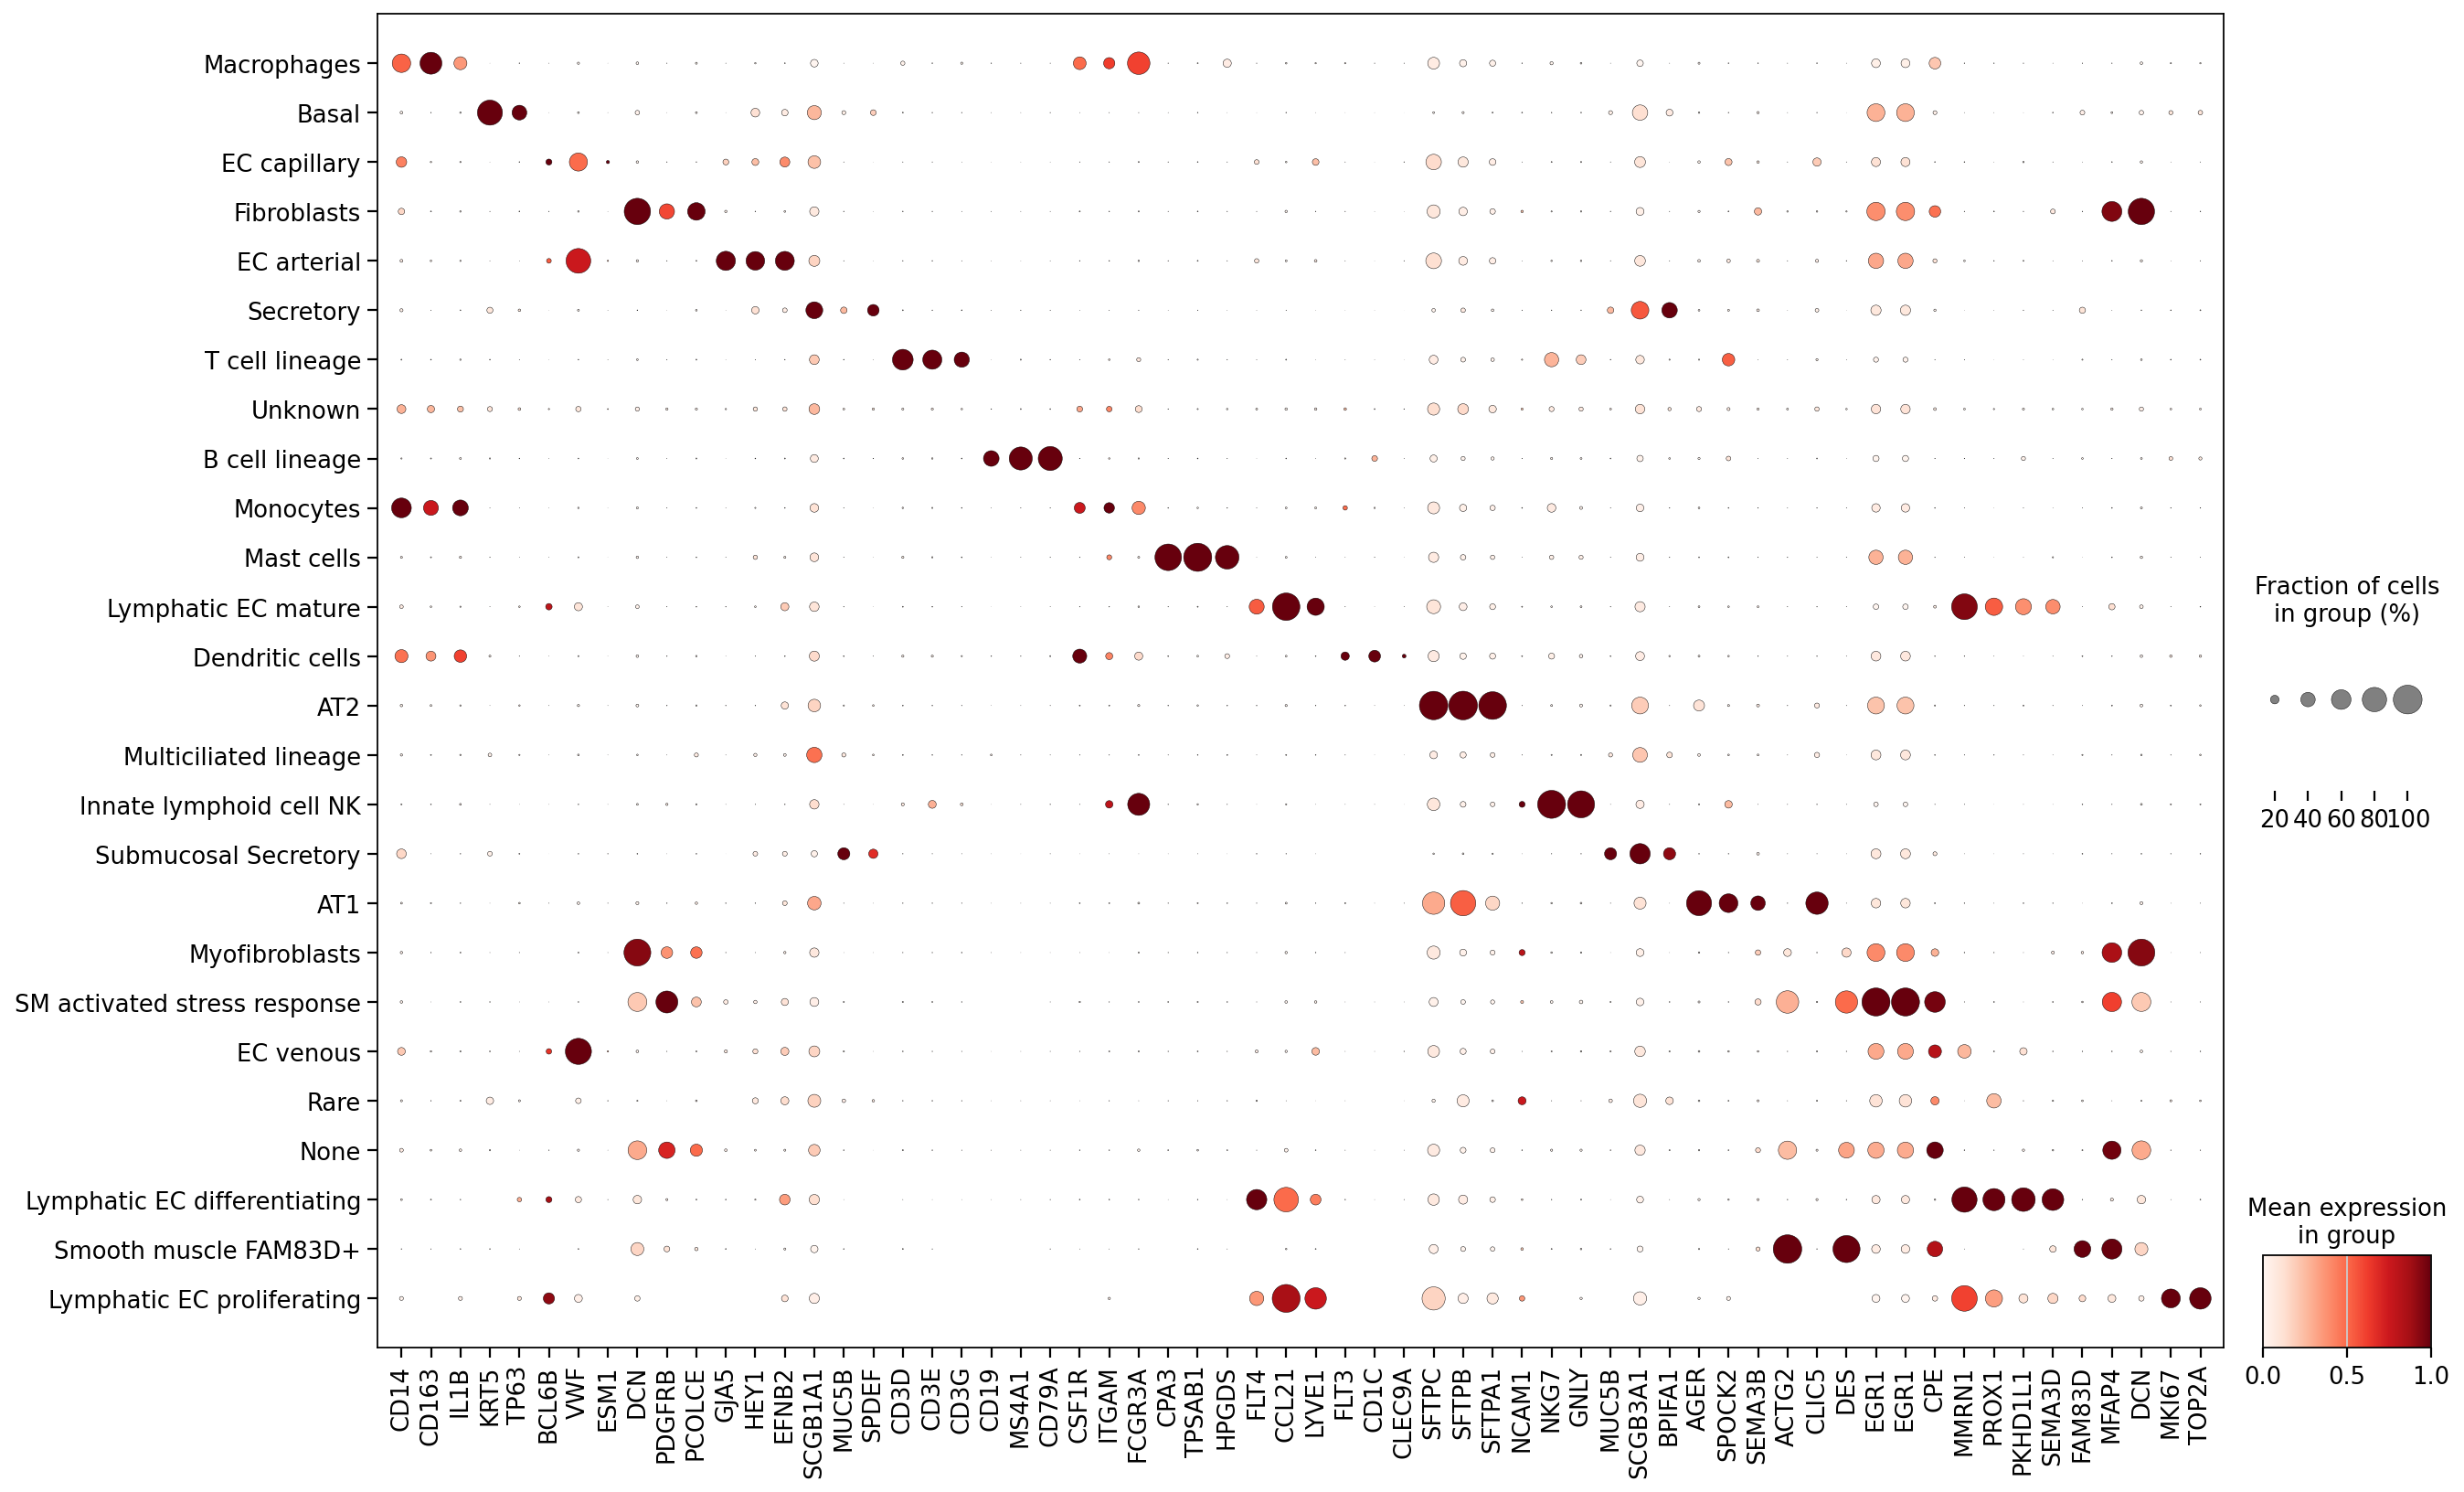

In [7]:
# Set figure parameters for Scanpy
sc.set_figure_params(scanpy=True, fontsize=14)

# Create a dot plot with specific genes using sc.pl.dotplot
sc.pl.dotplot(
    adata,
    var_names=updated_markers,
    groupby='ann_level_3',
    standard_scale='var',
    use_raw=False,
    figsize=(18,12 ),
    cmap='Reds',
    save="dotplot_figure.svg"  # Save the plot directly as an SVG
)

In [8]:
gc.collect()

17467

## 3. PCA, Harmony integration and UMAP

*Note*: Harmony batch correction is used only for this visualisation. The downstream analyses (NMF metaprograms, File 05) are run separately on each sample, so batch effects between datasets do not affect them.

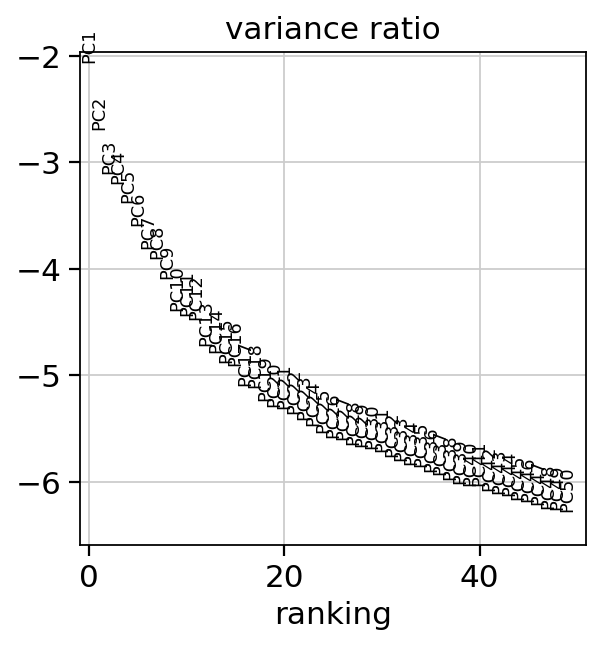

2025-06-25 20:46:44,488 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...



Computing initial centroids with sklearn.KMeans...



2025-06-25 20:51:08,394 - harmonypy - INFO - sklearn.KMeans initialization complete.



sklearn.KMeans initialization complete.



2025-06-25 20:51:14,136 - harmonypy - INFO - Iteration 1 of 10



...

2025-06-25 21:42:48,331 - harmonypy - INFO - Iteration 7 of 10



Iteration 7 of 10



2025-06-25 21:51:07,434 - harmonypy - INFO - Converged after 7 iterations



Converged after 7 iterations



2025-06-25 21:56:43.392126: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-06-25 21:56:43.410470: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750881403.432647 2882449 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750881403.439175 2882449 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-25 21:56:43.460425: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [9]:
# PCA without scaling: scaling makes the matrix dense and runs out of memory.
# The embedding is used only to visualise the atlas (atlas details: Sikkema et al. 2023).
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

# Integrate datasets using Harmony
sce.pp.harmony_integrate(adata, ['dataset','suspension_type'], basis='X_pca', adjusted_basis='X_pca_h')

# Neighbour graph and UMAP
sc.pp.neighbors(adata, use_rep="X_pca_h")
sc.tl.umap(adata)

## 4. UMAPs of cell types and AT2 markers (Figure 1A, D)

In [10]:
# AT2 cell markers
at2_markers = [
    "SFTPC",   # Surfactant Protein C
    "SFTPA1",  # Surfactant Protein A1
    "SFTPB",   # Surfactant Protein B
    "ABCA3",   # ATP Binding Cassette Subfamily A Member 3
]

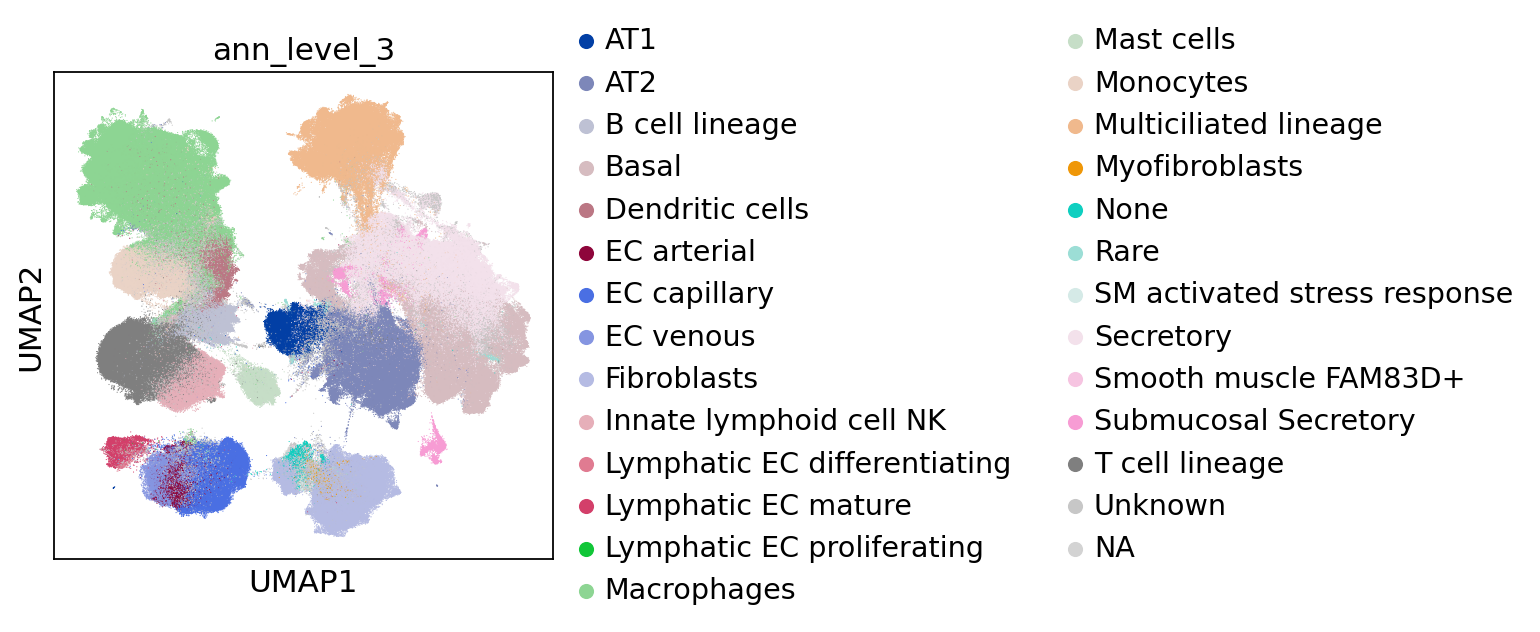

In [11]:
# Plot UMAP
sc.pl.umap(
    adata,
    color='ann_level_3',
    size=1,
    save='umap_plot_celltypes_normal.svg'
)

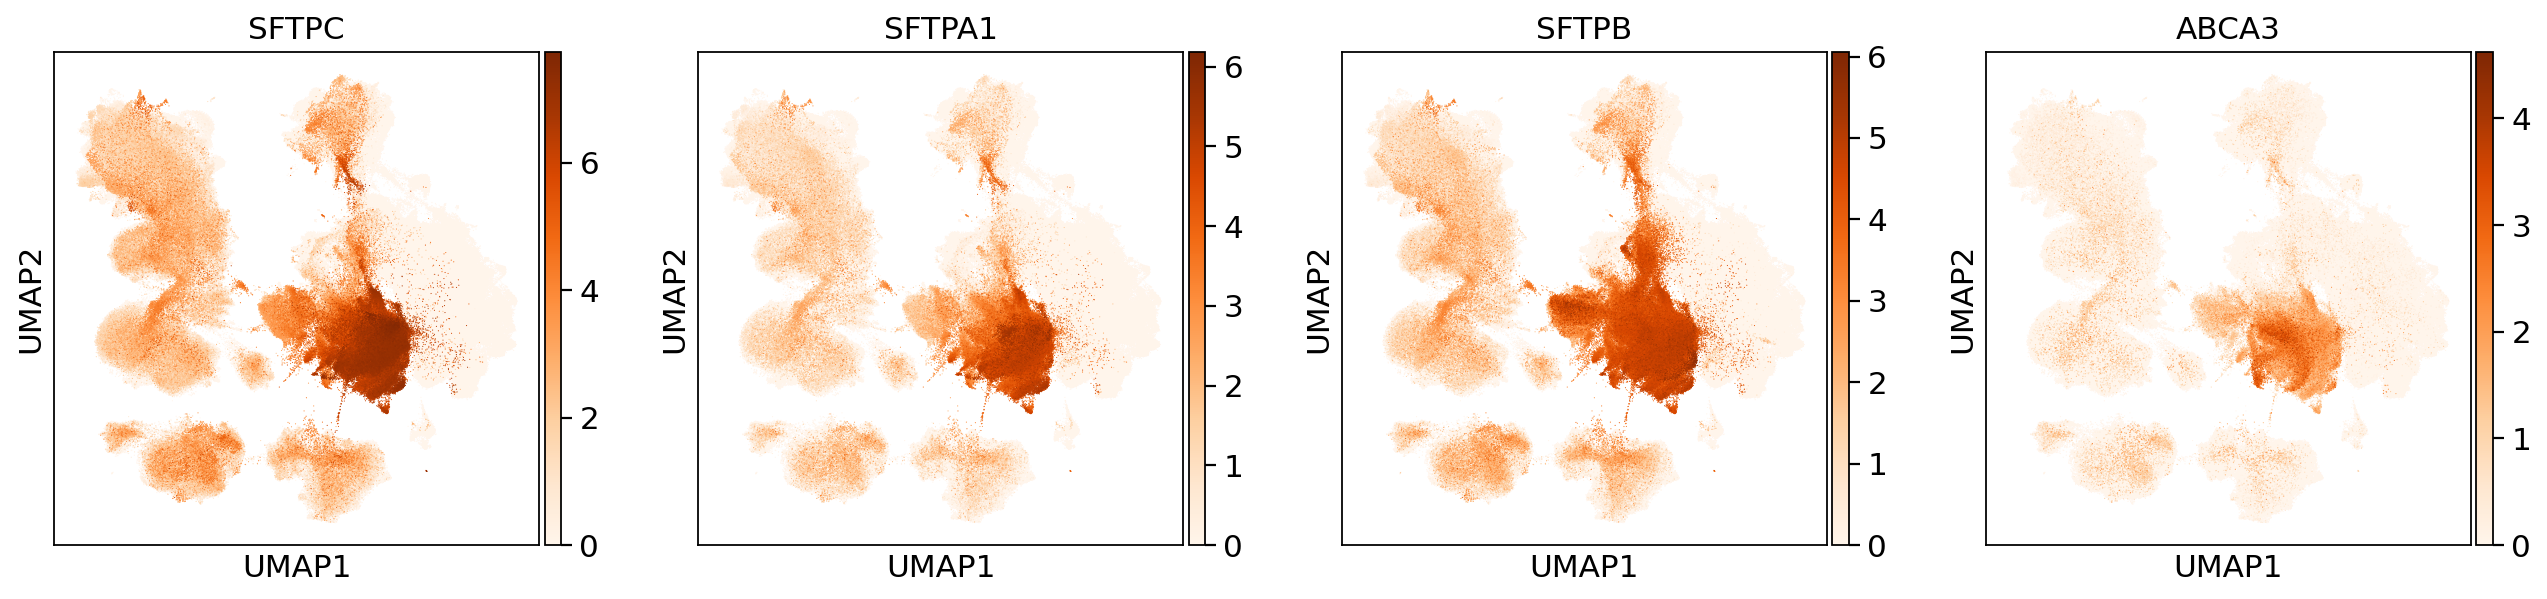

In [12]:
# Plot UMAP
sc.pl.umap(
    adata,
    color=at2_markers,
    color_map='Oranges',
    size=1,
    save='umap_plot_AT2_markers.svg'
)